In [1]:
import pandas as pd

DATASETS = {
    "jm1": "../data/jm1_clean.csv",
    "kc1": "../data/kc1.csv",
    "pc1": "../data/pc1.csv",
    "cm1": "../data/cm1.csv",
}

LABEL_CANDIDATES = ["defects", "problems"]
LABEL_MAP = {"true": 1, "false": 0, "yes": 1, "no": 0, "1": 1, "0": 0}


def load_dataset(path):
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]

    # Junk rows tabhi hatao jab pehli row ka loc 1.1 ho
    junk = 0
    if float(df.iloc[0, 0]) == 1.1:
        df = df.iloc[2:].reset_index(drop=True)
        junk = 2

    label_col = next(c for c in LABEL_CANDIDATES if c in df.columns)
    y = df[label_col].astype(str).str.strip().str.lower().map(LABEL_MAP)
    X = df.drop(columns=[label_col]).apply(pd.to_numeric, errors="coerce")

    out = X.copy()
    out["defects"] = y
    return out, junk


data, rows = {}, []
for name, path in DATASETS.items():
    df, junk = load_dataset(path)
    data[name] = df
    n_def = int(df["defects"].sum())
    rows.append({
        "dataset": name,
        "modules": len(df),
        "features": df.shape[1] - 1,
        "defective": n_def,
        "non_defective": len(df) - n_def,
        "defect_rate_%": round(100 * n_def / len(df), 1),
        "missing_values": int(df.isna().sum().sum()),
        "duplicates": int(df.duplicated().sum()),
        "junk_rows_removed": junk,
    })

pd.DataFrame(rows).set_index("dataset")

,modules,features,defective,non_defective,defect_rate_%,missing_values,duplicates,junk_rows_removed
dataset,,,,,,,,
jm1,10883,21,2105,8778,19.3,25,1973,2
kc1,2107,21,325,1782,15.4,0,897,2
pc1,1107,21,76,1031,6.9,0,155,2
cm1,496,21,48,448,9.7,0,56,2


In [2]:
df = data["jm1"]
print("shape:", df.shape)
print("duplicate rows:", df.duplicated().sum())
print("unique rows:", len(df.drop_duplicates()))
print(df["defects"].value_counts())


shape: (10883, 22)
duplicate rows: 1973
unique rows: 8910
defects
0    8778
1    2105
Name: count, dtype: int64


In [3]:
from sklearn.datasets import fetch_openml

jm1 = fetch_openml(data_id=1053, as_frame=True, parser="liac-arff").frame
label = jm1.columns[-1]
jm1[label] = jm1[label].astype(str).str.lower().map({"true": 1, "false": 0, "yes": 1, "no": 0})
jm1 = jm1.rename(columns={label: "defects"})

print(jm1.shape)
print(jm1["defects"].value_counts())
print("duplicates:", jm1.duplicated().sum())

jm1.to_csv("../data/jm1_clean.csv", index=False)


(10885, 22)
defects
0    8779
1    2106
Name: count, dtype: int64
duplicates: 1973


In [4]:
import os
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

SCORING = ["accuracy", "precision", "recall", "f1"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def make_model(name):
    if name == "RandomForest":
        clf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    else:
        clf = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                            eval_metric="logloss", random_state=42, n_jobs=-1)
    # SMOTE pipeline ke andar hai, isliye sirf training folds pe lagta hai (no leakage)
    return ImbPipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", MinMaxScaler()),
        ("smote", SMOTE(random_state=42)),
        ("clf", clf),
    ])


results = []
for ds_name, df in data.items():
    for variant, d in [("with_duplicates", df), ("no_duplicates", df.drop_duplicates())]:
        X = d.drop(columns="defects")
        y = d["defects"].astype(int)
        for model_name in ["RandomForest", "XGBoost"]:
            scores = cross_validate(make_model(model_name), X, y, cv=cv, scoring=SCORING)
            row = {"dataset": ds_name, "variant": variant, "model": model_name, "rows": len(d)}
            for m in SCORING:
                s = scores[f"test_{m}"]
                row[m] = f"{100 * s.mean():.1f} ± {100 * s.std():.1f}"
            results.append(row)

results_df = pd.DataFrame(results)
os.makedirs("../results", exist_ok=True)
results_df.to_csv("../results/baseline_results.csv", index=False)
results_df

,dataset,variant,model,rows,accuracy,precision,recall,f1
0,jm1,with_duplicates,RandomForest,10883,79.6 ± 0.7,46.8 ± 1.9,38.5 ± 2.3,42.2 ± 2.0
1,jm1,with_duplicates,XGBoost,10883,79.9 ± 0.5,47.1 ± 1.6,30.7 ± 1.6,37.1 ± 1.1
2,jm1,no_duplicates,RandomForest,8910,75.7 ± 0.4,44.8 ± 1.2,34.5 ± 0.7,39.0 ± 0.6
3,jm1,no_duplicates,XGBoost,8910,77.0 ± 0.8,48.3 ± 2.8,30.2 ± 1.6,37.1 ± 1.5
4,kc1,with_duplicates,RandomForest,2107,83.6 ± 1.2,47.0 ± 4.0,46.5 ± 2.8,46.7 ± 3.1
5,kc1,with_duplicates,XGBoost,2107,84.5 ± 1.7,50.2 ± 6.0,43.1 ± 4.1,46.2 ± 4.1
6,kc1,no_duplicates,RandomForest,1210,72.2 ± 1.9,46.2 ± 3.9,40.1 ± 3.0,42.9 ± 3.0
7,kc1,no_duplicates,XGBoost,1210,73.6 ± 1.9,48.6 ± 5.3,36.9 ± 4.6,42.0 ± 4.9
8,pc1,with_duplicates,RandomForest,1107,92.5 ± 1.0,44.2 ± 10.8,47.4 ± 20.9,44.7 ± 13.9
9,pc1,with_duplicates,XGBoost,1107,92.6 ± 1.2,46.4 ± 7.9,46.1 ± 7.4,46.2 ± 7.5


              precision    recall  f1-score   support

           0      0.819     0.867     0.842      1381
           1      0.425     0.339     0.377       401

    accuracy                          0.748      1782
   macro avg      0.622     0.603     0.610      1782
weighted avg      0.730     0.748     0.737      1782


Top 10 features (mean |SHAP|):
loc            0.0456
iv(g)          0.0450
lOBlank        0.0445
branchCount    0.0230
v(g)           0.0179
lOCode         0.0159
uniq_Opnd      0.0126
uniq_Op        0.0119
ev(g)          0.0117
d              0.0113
dtype: float64


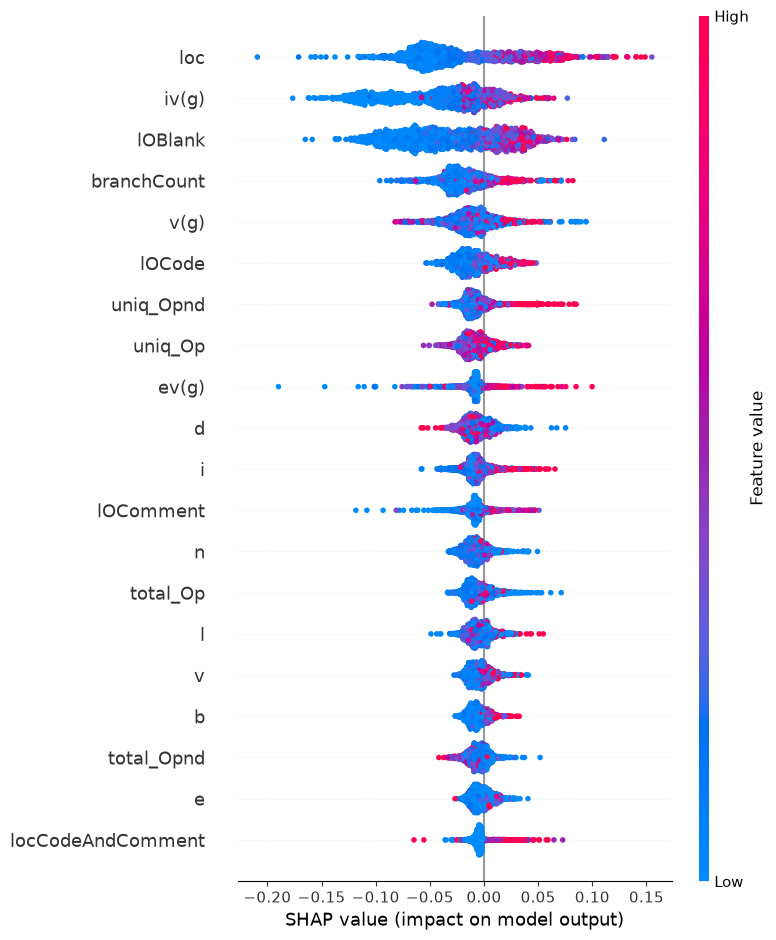


Chosen test module index: 1604 | predicted defect probability: 1.00

SHAP local contributions (top 8):
loc            0.1207
branchCount    0.0777
ev(g)          0.0610
iv(g)          0.0558
v(g)           0.0506
total_Op       0.0281
l              0.0243
n              0.0198
dtype: float64


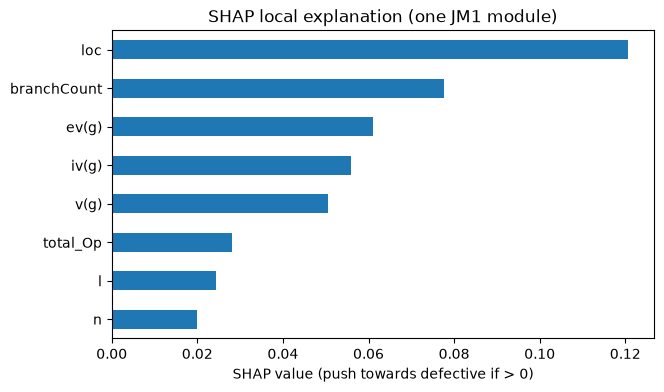


LIME explanation (top 8):
                        rule  weight
0                v(g) > 0.01 -0.0467
1            lOBlank <= 0.00 -0.0422
2               iv(g) > 0.01 -0.0267
3         branchCount > 0.02 -0.0213
4                 loc > 0.02 -0.0173
5                  i <= 0.03 -0.0134
6         total_Opnd <= 0.00  0.0121
7  locCodeAndComment <= 0.00 -0.0116


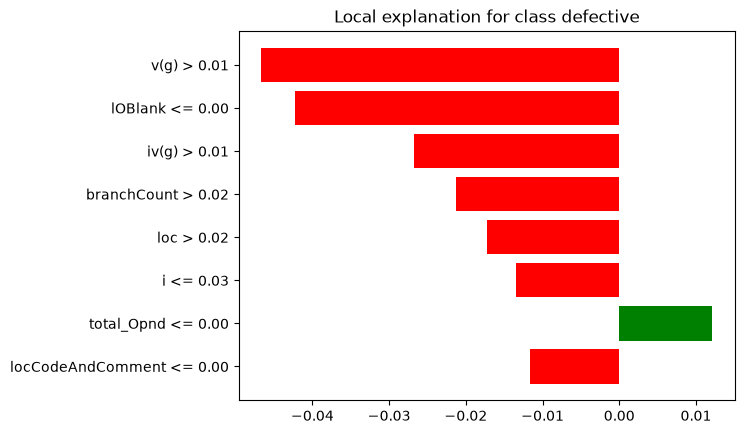

In [5]:
import os
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from imblearn.over_sampling import SMOTE

os.makedirs("../results", exist_ok=True)

# ---------- 1. Data + 80/20 stratified split (duplicates hatake) ----------
df = data["jm1"].drop_duplicates()
X = df.drop(columns="defects")
y = df["defects"].astype(int)
feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# ---------- 2. Preprocess (fit sirf train pe) + SMOTE sirf train pe ----------
imputer = SimpleImputer(strategy="median").fit(X_train)
scaler = MinMaxScaler().fit(imputer.transform(X_train))
prep = lambda A: scaler.transform(imputer.transform(A))

Xtr, Xte = prep(X_train), prep(X_test)
Xtr_sm, ytr_sm = SMOTE(random_state=42).fit_resample(Xtr, y_train)

# ---------- 3. Model ----------
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(Xtr_sm, ytr_sm)
print(classification_report(y_test, rf.predict(Xte), digits=3))

# ---------- 4. SHAP (global) ----------
explainer = shap.TreeExplainer(rf)
sv = explainer.shap_values(Xte)
if isinstance(sv, list):
    sv_pos = sv[1]
elif sv.ndim == 3:
    sv_pos = sv[:, :, 1]
else:
    sv_pos = sv

shap_imp = pd.Series(np.abs(sv_pos).mean(axis=0), index=feature_names).sort_values(ascending=False)
print("\nTop 10 features (mean |SHAP|):")
print(shap_imp.head(10).round(4))

shap.summary_plot(sv_pos, Xte, feature_names=feature_names, show=False)
plt.savefig("../results/shap_summary_jm1.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- 5. Ek module chuno: sabse confident true-positive ----------
proba = rf.predict_proba(Xte)[:, 1]
idx = int(np.argmax(proba * (y_test.values == 1)))
print(f"\nChosen test module index: {idx} | predicted defect probability: {proba[idx]:.2f}")

# ---------- 6. SHAP (local) ----------
loc_shap = pd.Series(sv_pos[idx], index=feature_names)
top_local = loc_shap.reindex(loc_shap.abs().sort_values(ascending=False).index)[:8]
print("\nSHAP local contributions (top 8):")
print(top_local.round(4))

plt.figure(figsize=(7, 4))
top_local[::-1].plot(kind="barh")
plt.title("SHAP local explanation (one JM1 module)")
plt.xlabel("SHAP value (push towards defective if > 0)")
plt.savefig("../results/shap_local_jm1.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- 7. LIME (same module) ----------
lime_explainer = LimeTabularExplainer(
    Xtr, feature_names=feature_names,
    class_names=["non-defective", "defective"],
    mode="classification", discretize_continuous=True, random_state=42,
)
exp = lime_explainer.explain_instance(Xte[idx], rf.predict_proba, num_features=8, num_samples=2000)
print("\nLIME explanation (top 8):")
print(pd.DataFrame(exp.as_list(), columns=["rule", "weight"]).round(4))

fig = exp.as_pyplot_figure()
fig.savefig("../results/lime_local_jm1.png", dpi=150, bbox_inches="tight")
plt.show()